In [1]:
import time
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import ccxt
from itertools import combinations
from statsmodels.tsa.stattools import coint
from scipy.stats import ttest_rel

pd.set_option("display.width", 140)

In [2]:
UNIVERSE = ["BTC", "ETH", "SOL", "BNB", "XRP", "DOGE", "ADA", "LINK", "AVAX", "DOT", 
            "LTC", "ATOM", "AAVE", "UNI", "ARB", "OP", "SUI", "NEAR", "ALGO", "FIL", 
            "MATIC", "TRX", "BCH", "ETC", "XLM", "ICP", "APT", "SEI", "INJ", "RENDER", 
            "FET", "TIA", "HBAR", "VET", "THETA", "EOS", "SAND", "MANA", "GRT", "MKR"]
SYMBOLS = [f"{coin}/USD" for coin in UNIVERSE]

In [3]:
exchange = ccxt.coinbase()
markets = exchange.load_markets()

symbols = [f"{coin}/USD" for coin in UNIVERSE if f"{coin}/USD" in markets]
pairs = list(combinations(symbols, 2))
print(f"{len(symbols)} coins available, {len(pairs)} candidate pairs")

37 coins available, 666 candidate pairs


In [4]:
def to_df(data, symbol):
    df = pd.DataFrame(data, columns=["timestamp", "open", "high", "low", "close", "volume"])
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df = df[["timestamp", "close", "volume"]].copy()
    df = df.rename(columns={"close": symbol, "volume": f"{symbol}_volume"})
    return df

In [5]:
exchange = ccxt.coinbase({
    "enableRateLimit": True,
    "timeout": 30000,  
})

def fetch_ohlcv_history(exchange, symbol, timeframe, since_ms, limit=300, max_retries=5):
    all_rows = []
    since = since_ms
    now_ms = exchange.milliseconds()

    while since < now_ms:
        batch = None
        for attempt in range(max_retries):
            try:
                batch = exchange.fetch_ohlcv(symbol, timeframe=timeframe, since=since, limit=limit)
                break
            except (ccxt.RequestTimeout, ccxt.NetworkError) as e:
                if attempt == max_retries - 1:
                    raise
                time.sleep(2 ** attempt)

        if not batch:
            break

        all_rows.extend(batch)
        since = batch[-1][0] + 1

    return all_rows

In [6]:
YEARS_OF_HISTORY = 5 
TIMEFRAME = "1h"

since_dt = pd.Timestamp.utcnow() - pd.DateOffset(years=YEARS_OF_HISTORY)
HISTORY_SINCE = exchange.parse8601(since_dt.strftime("%Y-%m-%dT%H:%M:%SZ"))

prices = None
for coin in UNIVERSE:
    symbol = f"{coin}/USD"
    if symbol not in markets:
        continue
    data = fetch_ohlcv_history(exchange, symbol, timeframe=TIMEFRAME, since_ms=HISTORY_SINCE)
    if not data:
        continue
    df = to_df(data, coin)
    prices = df if prices is None else prices.merge(df, on="timestamp", how="inner")

prices = prices.sort_values("timestamp").reset_index(drop=True)
print(f"{len(prices)} aligned hourly bars, {prices['timestamp'].min()} -> {prices['timestamp'].max()}")

/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_46579/1872878780.py:4: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  since_dt = pd.Timestamp.utcnow() - pd.DateOffset(years=YEARS_OF_HISTORY)


37747 aligned hourly bars, 2021-08-18 20:00:00 -> 2025-12-10 19:00:00


In [7]:
# Keep the original 1h data so we can compare 4h / 8h / 12h later.
prices_1h = prices.copy()

# Main run stays at 4h, just like the original notebook.
prices = prices_1h.set_index("timestamp").resample("4h").agg({
    **{c: "last" for c in UNIVERSE if c in prices_1h.columns},
    **{f"{c}_volume": "sum" for c in UNIVERSE if f"{c}_volume" in prices_1h.columns},
}).dropna().reset_index()


In [8]:
available_assets = [c for c in UNIVERSE if c in prices.columns]
symbols = [f"{c}/USD" for c in available_assets]
pairs = list(combinations(symbols, 2))

In [9]:
TRAIN_FRAC = 0.7

split_idx = int(len(prices) * TRAIN_FRAC)
train_prices = prices.iloc[:split_idx].reset_index(drop=True)
test_prices = prices.iloc[split_idx:].reset_index(drop=True)

print(f"Train: {train_prices['timestamp'].min()} -> {train_prices['timestamp'].max()}  ({len(train_prices)} bars)")
print(f"Test:  {test_prices['timestamp'].min()} -> {test_prices['timestamp'].max()}  ({len(test_prices)} bars)")

Train: 2021-08-18 20:00:00 -> 2024-08-25 00:00:00  (6614 bars)
Test:  2024-08-25 04:00:00 -> 2025-12-10 16:00:00  (2835 bars)


In [10]:
def align_pair_prices(prices, asset_a, asset_b):
    cols = ["timestamp", asset_a, asset_b]
    vol_cols = [f"{asset_a}_volume", f"{asset_b}_volume"]
    needed = cols + [c for c in vol_cols if c in prices.columns]
    out = prices[needed].dropna().copy()
    out = out.sort_values("timestamp").reset_index(drop=True)
    return out

In [11]:
def estimate_ols_spread(df, asset_a, asset_b):
    """
    Fit the hedge ratio via OLS (used ONLY on the train set) and run the
    Engle-Granger cointegration test on the two log-price series.
    Two nonstationary series can produce a highly significant OLS slope
    just because both trend -- that p-value is NOT a cointegration test,
    so we report the Engle-Granger p-value instead.
    """
    out = df.copy()
    out[f"log_{asset_a}"] = np.log(out[asset_a])
    out[f"log_{asset_b}"] = np.log(out[asset_b])

    X = sm.add_constant(out[f"log_{asset_b}"])
    y = out[f"log_{asset_a}"]
    model = sm.OLS(y, X).fit()
    
    alpha = model.params["const"]
    beta = model.params[f"log_{asset_b}"]
    corr = out[[f"log_{asset_a}", f"log_{asset_b}"]].corr().iloc[0, 1]
    out["spread"] = model.resid

    eg_stat, eg_pvalue, eg_crit = coint(out[f"log_{asset_a}"], out[f"log_{asset_b}"])

    return out, alpha, beta, corr, eg_pvalue

In [12]:
def apply_fixed_spread(df, asset_a, asset_b, alpha, beta):
    """
    Build the spread on a NEW sample (e.g. the test set) using an alpha/beta
    that was already estimated elsewhere (the train set). No refitting here,
    so no look-ahead when this is used out-of-sample.
    """
    out = df.copy()
    out[f"log_{asset_a}"] = np.log(out[asset_a])
    out[f"log_{asset_b}"] = np.log(out[asset_b])
    out["spread"] = out[f"log_{asset_a}"] - (alpha + beta * out[f"log_{asset_b}"])
    return out

In [13]:
def spread_half_life(spread):
    s = pd.Series(spread).dropna()
    lag = s.shift(1)
    diff = s - lag
    tmp = pd.concat([diff, lag], axis=1).dropna()
    tmp.columns = ["diff", "lag"]
    if len(tmp) < 5:
        return np.nan
    model = sm.OLS(tmp["diff"], sm.add_constant(tmp["lag"])).fit()
    lam = model.params["lag"]
    if lam >= 0:
        return np.nan
    return -np.log(2) / lam

In [14]:
def spread_crossings(z, threshold=2.0):
    z = pd.Series(z).dropna()
    if len(z) < 2:
        return 0
    upper = ((z.shift(1) < threshold) & (z >= threshold)).sum()
    lower = ((z.shift(1) > -threshold) & (z <= -threshold)).sum()
    return int(upper + lower)

In [15]:
def simple_beta_stability(df, asset_a, asset_b):
    """Compare the hedge ratio in the first half vs second half of training data."""
    mid = len(df) // 2
    if mid < 20:
        return np.nan

    def get_beta(x):
        la = np.log(x[asset_a])
        lb = np.log(x[asset_b])
        return sm.OLS(la, sm.add_constant(lb)).fit().params.iloc[1]

    b1 = get_beta(df.iloc[:mid])
    b2 = get_beta(df.iloc[mid:])
    if b1 == 0 or np.isnan(b1) or np.isnan(b2):
        return np.nan
    return abs(b2 - b1) / abs(b1)


def pair_summary(prices, asset_a, asset_b, crossing_z=2.0):
    df, alpha, beta, corr, eg_pvalue = estimate_ols_spread(prices, asset_a, asset_b)

    spread = df["spread"].dropna()
    spread_vol = spread.std()
    hl = spread_half_life(spread)

    z = (spread - spread.mean()) / spread.std()
    crossings = spread_crossings(z, threshold=crossing_z)
    beta_stability = simple_beta_stability(df, asset_a, asset_b)

    return pd.Series({
        "Pair": f"{asset_a}/{asset_b}",
        "Asset_A": asset_a,
        "Asset_B": asset_b,
        "Corr": corr,
        "EG_Coint_Pvalue": eg_pvalue,
        "Alpha": alpha,
        "Beta": beta,
        "Spread_Vol": spread_vol,
        "Half_life": hl,
        "Z_score_Crossings": crossings,
        "Beta_Stability": beta_stability
    })


In [16]:
candidate_rows = []
for a, b in pairs:
    candidate_rows.append(pair_summary(train_prices, a.split("/")[0], b.split("/")[0]))

pair_table = pd.DataFrame(candidate_rows).sort_values("EG_Coint_Pvalue")

# Simple training-period filters.
result = pair_table.query("Corr > 0.8")
result = result.query("EG_Coint_Pvalue < 0.1")
result = result.query("Half_life >= 12 and Half_life <= 600")
result = result.query("Beta_Stability <= 0.35")
result = result.sort_values("Z_score_Crossings", ascending=False)

base_pairs = result.reset_index(drop=True)
print(f"{len(base_pairs)} pairs passed the statistical screen")
base_pairs.head(10)


20 pairs passed the statistical screen


,Pair,Asset_A,Asset_B,Corr,EG_Coint_Pvalue,Alpha,Beta,Spread_Vol,Half_life,Z_score_Crossings,Beta_Stability
0,DOGE/ICP,DOGE,ICP,0.899322,0.022402,-3.370107,0.491335,0.193141,173.449048,35,0.027388
1,UNI/GRT,UNI,GRT,0.911823,0.067593,3.030135,0.586876,0.204370,202.249815,34,0.223892
2,DOGE/UNI,DOGE,UNI,0.911779,0.034579,-3.948095,0.809055,0.181389,147.922712,31,0.205417
3,ETC/ICP,ETC,ICP,0.883924,0.017410,2.322033,0.408237,0.174600,180.850780,30,0.028442
4,BCH/MKR,BCH,MKR,0.946302,0.004642,-1.829642,1.006185,0.190190,148.398459,30,0.241131
5,DOT/FIL,DOT,FIL,0.981192,0.000132,0.656040,0.718753,0.128778,102.391236,25,0.133421
6,ADA/FIL,ADA,FIL,0.976572,0.005658,-2.018070,0.667972,0.134049,137.347366,25,0.295375
7,UNI/ICP,UNI,ICP,0.931250,0.014208,0.789595,0.573377,0.181374,163.277499,24,0.213999
8,UNI/ETC,UNI,ETC,0.900860,0.043898,-1.814887,1.200975,0.216081,198.966365,24,0.008825
9,AAVE/FIL,AAVE,FIL,0.947118,0.045039,3.535320,0.522494,0.161218,150.860796,24,0.050910


In [17]:
def rolling_zscore(series, window=25):
    mean = series.rolling(window).mean()
    std = series.rolling(window).std()
    return (series - mean) / std

In [18]:
def build_zscore_positions(z, entry_z=2.0, exit_z=0.25, min_persist=4, cooldown_bars=0, allow_entry=None):
    position = 0
    cooldown = 0
    below_count = 0
    above_count = 0
    positions = []

    for i, val in enumerate(z):
        if pd.isna(val):
            positions.append(0)
            continue

        if val < -entry_z:
            below_count += 1
        else:
            below_count = 0

        if val > entry_z:
            above_count += 1
        else:
            above_count = 0

        if cooldown > 0:
            cooldown -= 1

        entry_ok = True if allow_entry is None else bool(allow_entry.iloc[i])

        if position == 0:
            if cooldown == 0 and entry_ok and below_count >= min_persist:
                position = 1
            elif cooldown == 0 and entry_ok and above_count >= min_persist:
                position = -1

        elif position == 1:
            if val > -exit_z:
                position = 0
                cooldown = cooldown_bars

        elif position == -1:
            if val < exit_z:
                position = 0
                cooldown = cooldown_bars

        positions.append(position)

    return pd.Series(positions, index=z.index)

In [19]:
def build_bollinger_positions(spread, window=25, band_k=1.0, min_persist=4, cooldown_bars=0, allow_entry=None):
    smooth_spread = spread.rolling(3).mean()
    mid = smooth_spread.rolling(window).mean()
    std = smooth_spread.rolling(window).std()
    upper = mid + band_k * std
    lower = mid - band_k * std

    position = 0
    cooldown = 0
    below_count = 0
    above_count = 0
    positions = []

    for i, (s, m, u, l) in enumerate(zip(smooth_spread, mid, upper, lower)):
        if pd.isna(s) or pd.isna(m) or pd.isna(u) or pd.isna(l):
            positions.append(0)
            continue

        if s < l:
            below_count += 1
        else:
            below_count = 0

        if s > u:
            above_count += 1
        else:
            above_count = 0

        if cooldown > 0:
            cooldown -= 1

        entry_ok = True if allow_entry is None else bool(allow_entry.iloc[i])

        if position == 0:
            if cooldown == 0 and entry_ok and below_count >= min_persist:
                position = 1
            elif cooldown == 0 and entry_ok and above_count >= min_persist:
                position = -1

        elif position == 1:
            if s >= m:
                position = 0
                cooldown = cooldown_bars

        elif position == -1:
            if s <= m:
                position = 0
                cooldown = cooldown_bars

        positions.append(position)

    out = pd.Series(positions, index=spread.index)
    return out, mid, upper, lower

In [20]:
ANN_FACTOR_HOURLY = np.sqrt(6 * 365)

def backtest_pair_strategy(
    prices, asset_a, asset_b, alpha, beta,
    strategy="zscore", window=25, entry_z=2.0, exit_z=0.25, band_k=1.0,
    fee_bps=20.0,
    min_persist=2,
    cooldown_bars=0,
    vol_window=50,
    vol_zmax=1.5,
    cost_buffer=1.0
):
    df = align_pair_prices(prices, asset_a, asset_b)
    df = apply_fixed_spread(df, asset_a, asset_b, alpha, beta)

    df["spread_mean"] = df["spread"].rolling(window).mean()
    df["spread_std"] = df["spread"].rolling(window).std()

    # Simple volume idea:
    # low relative volume -> 1.25x exposure
    # normal volume      -> 1.00x exposure
    # high volume        -> 0.50x exposure
    # very high volume   -> 0x exposure
    vol_a = f"{asset_a}_volume"
    vol_b = f"{asset_b}_volume"
    if vol_a in df.columns and vol_b in df.columns:
        rel_a = df[vol_a] / df[vol_a].rolling(vol_window).median()
        rel_b = df[vol_b] / df[vol_b].rolling(vol_window).median()
        df["relative_volume"] = (rel_a + rel_b) / 2
        vol_mean = df["relative_volume"].rolling(vol_window).mean()
        vol_std = df["relative_volume"].rolling(vol_window).std()
        df["volume_z"] = (df["relative_volume"] - vol_mean) / vol_std
        df["volume_scale"] = np.where(
            df["volume_z"] >= 2.0, 0.0,
            np.where(df["volume_z"] >= 1.0, 0.5,
                     np.where(df["volume_z"] <= -1.0, 1.25, 1.0))
        )
        df["volume_ok"] = df["volume_scale"] > 0
    else:
        df["volume_scale"] = 1.0
        df["volume_ok"] = True

    if strategy == "zscore":
        df["zscore"] = rolling_zscore(df["spread"], window=window)
        # expected_move = df["zscore"].abs() * df["spread_std"]
        # round_trip_cost = 2 * fee_bps / 10000.0
        # df["trade_ok"] = expected_move > cost_buffer * round_trip_cost
        # allow_entry = df["volume_ok"] & df["trade_ok"]
        allow_entry = df["volume_ok"] 

        z_smooth = df["zscore"].rolling(3).mean()

        df["position"] = build_zscore_positions(
            z_smooth, entry_z=entry_z, exit_z=exit_z,
            min_persist=min_persist, cooldown_bars=cooldown_bars,
            allow_entry=allow_entry
        )

    elif strategy == "bollinger":
        df["position"], df["bb_mid"], df["bb_upper"], df["bb_lower"] = build_bollinger_positions(
            df["spread"], window=window, band_k=band_k,
            min_persist=min_persist, cooldown_bars=cooldown_bars,
            allow_entry=df["volume_ok"]
        )

        # spread_dist = (df["spread"] - df["bb_mid"]).abs()
        # round_trip_cost = 2 * fee_bps / 10000.0
        # df["trade_ok"] = spread_dist > cost_buffer * round_trip_cost
        # df["position"] = df["position"].where(df["trade_ok"] & df["volume_ok"], 0)
        df["position"] = df["position"].where(df["volume_ok"], 0)

    else:
        raise ValueError("strategy must be 'zscore' or 'bollinger'")

    # Adjust exposure using the volume signal.
    df["position"] = df["position"] * df["volume_scale"]

    gross = 1 + abs(beta)
    df["w_a"] = df["position"] / gross
    df["w_b"] = -beta * df["position"] / gross

    df[f"ret_{asset_a}"] = df[asset_a].pct_change()
    df[f"ret_{asset_b}"] = df[asset_b].pct_change()

    raw_ret = (
        df["w_a"].shift(1) * df[f"ret_{asset_a}"] +
        df["w_b"].shift(1) * df[f"ret_{asset_b}"]
    )
    df["raw_ret"] = raw_ret

    turnover = (
        df["w_a"].diff().abs().fillna(0) +
        df["w_b"].diff().abs().fillna(0)
    )
    df["turnover"] = turnover

    cost_per_turn = fee_bps / 10000.0
    df["strategy_ret"] = raw_ret - turnover * cost_per_turn
    gross_sharpe = (
        raw_ret.mean() / raw_ret.std()
    ) * ANN_FACTOR_HOURLY if raw_ret.std() != 0 and not np.isnan(raw_ret.std()) else np.nan

    df = df.set_index("timestamp")
    df["equity"] = (1 + df["strategy_ret"].fillna(0)).cumprod()

    r = df["strategy_ret"].dropna()
    sharpe = (r.mean() / r.std()) * ANN_FACTOR_HOURLY if r.std() not in (0,) and not np.isnan(r.std()) else np.nan
    max_dd = (df["equity"] / df["equity"].cummax() - 1).min()
    cum_ret = df["equity"].iloc[-1] - 1 if len(df) else np.nan
    trades = (df["position"].diff().fillna(0) != 0).sum()

    metrics = pd.Series({
        "Pair": f"{asset_a}/{asset_b}", "Strategy": strategy,
        "Alpha": alpha, "Beta": beta, "Gross Sharpe": gross_sharpe, "Sharpe": sharpe,
        "Cumulative Return": cum_ret, "Max Drawdown": max_dd,
        "Trades": int(trades), "Avg Turnover/Bar": turnover.mean(),
        "Mean Hourly Return": r.mean(), "Vol Hourly": r.std(),
    })
    return df, metrics


In [21]:
FEE_BPS_MAIN = 20.0   # course assumption for crypto market orders -- lead with this
WINDOW = 25  # baseline; use grid-search results for comparison
Z_ENTRY = 2.5
Z_EXIT = 0.5
BB_K = 1.5


def run_pairs(prices_slice, selected_pairs, strategy, param_value, fee_bps, window=WINDOW, exit_z=Z_EXIT, min_persist=2, cooldown_bars=0, vol_window=50, vol_zmax=1.5, cost_buffer=1.0):
    bts = {}
    ret_series = {}
    metrics_rows = []

    for _, row in selected_pairs.iterrows():
        a, b = row["Asset_A"], row["Asset_B"]
        kwargs = dict(
            window=window,
            fee_bps=fee_bps,
            min_persist=min_persist,
            cooldown_bars=cooldown_bars,
            vol_window=vol_window,
            vol_zmax=vol_zmax,
            cost_buffer=cost_buffer
        )

        if strategy == "zscore":
            kwargs.update(entry_z=param_value, exit_z=exit_z)
        else:
            kwargs.update(band_k=param_value)

        bt, m = backtest_pair_strategy(
            prices_slice, a, b,
            alpha=row["Alpha"], beta=row["Beta"],
            strategy=strategy, **kwargs
        )

        pair_name = f"{a}/{b}"
        bts[pair_name] = bt
        ret_series[pair_name] = bt["strategy_ret"].rename(pair_name)
        metrics_rows.append(m)

    return bts, ret_series, pd.DataFrame(metrics_rows)

In [42]:
def quarterly_walkforward(
    prices,
    start_date,
    lookback,
    strategy="zscore",
    param_value=Z_ENTRY,
    fee_bps=FEE_BPS_MAIN,
    window=WINDOW,
    exit_z=Z_EXIT,
    max_pairs=12,
    min_persist=2,
    cooldown_bars=0
):
    """
    Quarterly point-in-time pair selection and hedge-ratio estimation.

    At the beginning of each quarter:
      1. Take only trailing data available before the quarter.
      2. Re-screen all candidate pairs.
      3. Select the best pairs using only trailing data.
      4. Estimate alpha/beta on that trailing data.
      5. Trade the selected pairs during the following quarter
         using fixed alpha/beta and fixed portfolio weights.
    """

    prices = prices.sort_values("timestamp").reset_index(drop=True)

    results = []
    quarter_info = []
    weights_records = []
    pair_bts_all = {}

    test_prices = prices[prices["timestamp"] >= start_date].copy()

    # Calendar quarter containing each bar
    test_prices["quarter"] = test_prices["timestamp"].dt.to_period("Q")

    for quarter, quarter_data in test_prices.groupby("quarter"):

        quarter_start = quarter_data["timestamp"].min()

        # ---------------------------------------------------------
        # Only information available BEFORE this quarter
        # ---------------------------------------------------------
        historical = prices[
            prices["timestamp"] < quarter_start
        ].copy()

        if len(historical) < lookback:
            continue

        trailing = historical.iloc[-lookback:].copy()

        # ---------------------------------------------------------
        # 1. Re-estimate pair statistics using trailing data only
        # ---------------------------------------------------------
        candidate_rows = []

        for a, b in pairs:
            candidate_rows.append(
                pair_summary(
                    trailing,
                    a.split("/")[0],
                    b.split("/")[0]
                )
            )

        pair_table_q = pd.DataFrame(candidate_rows)

        # Same filters as your original strategy
        eligible = pair_table_q.query("Corr > 0.8")
        eligible = eligible.query("EG_Coint_Pvalue < 0.1")
        eligible = eligible.query(
            "Half_life >= 12 and Half_life <= 600"
        )
        eligible = eligible.query(
            "Beta_Stability <= 0.35"
        )

        eligible = eligible.sort_values(
            "Z_score_Crossings",
            ascending=False
        ).reset_index(drop=True)

        if len(eligible) == 0:
            continue

        # ---------------------------------------------------------
        # 2. Evaluate eligible pairs using ONLY trailing data
        # ---------------------------------------------------------
        train_bts, train_rets, train_metrics = run_pairs(
            trailing,
            eligible,
            strategy,
            param_value,
            fee_bps,
            window=window,
            exit_z=exit_z,
            min_persist=min_persist,
            cooldown_bars=cooldown_bars
        )

        # Select best pairs using ONLY trailing information
        quality = (
            train_metrics[
                ["Pair", "Sharpe", "Avg Turnover/Bar"]
            ]
            .sort_values("Sharpe", ascending=False)
            .head(max_pairs)
        )

        selected = eligible[
            eligible["Pair"].isin(quality["Pair"])
        ].reset_index(drop=True)

        if len(selected) == 0:
            continue

        # ---------------------------------------------------------
        # 3. Calculate portfolio weights using trailing data
        # ---------------------------------------------------------
        selected_rets = {
            pair: train_rets[pair]
            for pair in train_rets
            if pair in selected["Pair"].values
        }

        selected_metrics = train_metrics[
            train_metrics["Pair"].isin(selected["Pair"])
        ].copy()

        weights, _ = quality_weights_from_returns(
            selected_rets,
            selected_metrics
        )

        # Store weights for this quarter
        quarter_weights = weights.to_dict()
        weights_records.append({
            "Quarter": str(quarter),
            **quarter_weights
        })

        # ---------------------------------------------------------
        # 4. Trade following quarter using FIXED alpha/beta
        # ---------------------------------------------------------
        quarter_data_clean = quarter_data.drop(
            columns=["quarter"]
        )

        quarter_bts, quarter_rets, quarter_metrics = run_pairs(
            quarter_data_clean,
            selected,
            strategy,
            param_value,
            fee_bps,
            window=window,
            exit_z=exit_z,
            min_persist=min_persist,
            cooldown_bars=cooldown_bars
        )

        # Save pair-level backtests so downstream turnover analysis can use them.
        for pair_name, bt in quarter_bts.items():
            pair_bts_all.setdefault(pair_name, []).append(bt)

        # Apply weights determined BEFORE the quarter began
        quarter_port_ret, applied_weights, _ = apply_fixed_weights(
            quarter_rets,
            weights
        )

        # Store quarterly portfolio returns
        results.append(quarter_port_ret)

        # Store quarter-level information
        quarter_info.append({
            "Quarter": str(quarter),
            "N_Eligible": len(eligible),
            "N_Selected": len(selected),
            "Selected_Pairs": selected["Pair"].tolist()
        })

    # -------------------------------------------------------------
    # No results
    # -------------------------------------------------------------
    if not results:
        return (
            pd.Series(dtype=float),
            pd.Series(dtype=float),
            pd.DataFrame(),
            pd.DataFrame()
        )

    # -------------------------------------------------------------
    # Combine quarterly portfolio returns
    # -------------------------------------------------------------
    portfolio_returns = pd.concat(results).sort_index()

    # -------------------------------------------------------------
    # Create cumulative portfolio equity
    # -------------------------------------------------------------
    portfolio_equity = (1 + portfolio_returns).cumprod()

    # -------------------------------------------------------------
    # Create quarter-by-quarter weights DataFrame
    # -------------------------------------------------------------
    weights_df = pd.DataFrame(weights_records)

    if not weights_df.empty:
        weights_df = (
            weights_df
            .set_index("Quarter")
            .fillna(0.0)
        )

    # -------------------------------------------------------------
    # Quarter information DataFrame
    # -------------------------------------------------------------
    quarter_info = pd.DataFrame(quarter_info)

    # Combine each pair's quarterly backtests into one DataFrame
    combined_pair_bts = {}

    for pair_name, bt_list in pair_bts_all.items():
        combined_pair_bts[pair_name] = pd.concat(
            bt_list,
            axis=0
        ).sort_index()

    return portfolio_returns, portfolio_equity, weights_df, quarter_info, combined_pair_bts

In [23]:
def equal_vol_weights_from_returns(ret_series):
    rets = pd.concat(ret_series.values(), axis=1, join="inner").dropna(how="any")
    vols = rets.std()
    inv_vol = 1 / vols.replace(0, np.nan)
    weights = inv_vol / inv_vol.sum()
    return weights, rets


def quality_weights_from_returns(ret_series, metrics):
    """Simple upgrade: inverse-vol * net Sharpe / turnover / correlation."""
    rets = pd.concat(ret_series.values(), axis=1, join="inner").dropna(how="any")
    vols = rets.std()
    inv_vol = 1 / vols.replace(0, np.nan)

    m = metrics.set_index("Pair")
    sharpe = m["Sharpe"].reindex(rets.columns).clip(-0.5, 0.5).fillna(0)
    turnover = m["Avg Turnover/Bar"].reindex(rets.columns).fillna(0)
    avg_corr = rets.corr().abs().mean().reindex(rets.columns).fillna(0)

    score = (
        inv_vol
        * (1 + sharpe)
        / (1 + turnover)
        / (1 + avg_corr)
    )

    if score.sum() == 0:
        return equal_vol_weights_from_returns(ret_series)
    return score / score.sum(), rets


In [24]:
# ----- Z-score selects its own pairs -----

z_train_bts, z_train_rets, z_train_metrics = run_pairs(
    train_prices, base_pairs, "zscore", Z_ENTRY, FEE_BPS_MAIN,
    min_persist=4, cooldown_bars=12, vol_zmax=1.5, cost_buffer=1.0
)

z_quality = z_train_metrics[["Pair", "Sharpe", "Avg Turnover/Bar"]].copy()
z_quality = z_quality.sort_values("Sharpe", ascending=False)

z_selected_pairs = base_pairs[
    base_pairs["Pair"].isin(z_quality.head(12)["Pair"])
].reset_index(drop=True)

print("Z-score selected pairs:")
print(z_selected_pairs["Pair"].tolist())

# ----- Bollinger selects its own pairs -----

bb_train_bts, bb_train_rets, bb_train_metrics = run_pairs(
    train_prices, base_pairs, "bollinger", BB_K, FEE_BPS_MAIN,
    min_persist=4, cooldown_bars=12, vol_zmax=1.5, cost_buffer=1.0
)

bb_quality = bb_train_metrics[["Pair", "Sharpe", "Avg Turnover/Bar"]].copy()
bb_quality = bb_quality.sort_values("Sharpe", ascending=False)

bb_selected_pairs = base_pairs[
    base_pairs["Pair"].isin(bb_quality.head(12)["Pair"])
].reset_index(drop=True)

print("\nBollinger selected pairs:")
print(bb_selected_pairs["Pair"].tolist())


Z-score selected pairs:
['UNI/GRT', 'ETC/ICP', 'BCH/MKR', 'UNI/ETC', 'AAVE/FIL', 'ATOM/EOS', 'ICP/GRT', 'AAVE/GRT', 'ETH/BCH', 'ALGO/EOS', 'ADA/DOT', 'ADA/ALGO']

Bollinger selected pairs:
['UNI/GRT', 'DOGE/UNI', 'DOT/FIL', 'ADA/FIL', 'UNI/ICP', 'UNI/ETC', 'AAVE/FIL', 'DOGE/LINK', 'ATOM/EOS', 'AAVE/GRT', 'ALGO/EOS', 'ADA/ALGO']


In [25]:
z_train_bts, z_train_rets, z_train_metrics = run_pairs(
    train_prices, z_selected_pairs, "zscore", Z_ENTRY, FEE_BPS_MAIN,
    min_persist=4, cooldown_bars=12, vol_zmax=1.5, cost_buffer=1.0
)

bb_train_bts, bb_train_rets, bb_train_metrics = run_pairs(
    train_prices, bb_selected_pairs, "bollinger", BB_K, FEE_BPS_MAIN,
    min_persist=4, cooldown_bars=12, vol_zmax=1.5, cost_buffer=1.0
)

# Keep equal-volatility as the baseline.
z_weights_equal, _ = equal_vol_weights_from_returns(z_train_rets)
bb_weights_equal, _ = equal_vol_weights_from_returns(bb_train_rets)

# Simple quality-adjusted weights.
z_weights, _ = quality_weights_from_returns(z_train_rets, z_train_metrics)
bb_weights, _ = quality_weights_from_returns(bb_train_rets, bb_train_metrics)

print("Selected pairs:")
print(base_pairs[["Pair", "Half_life", "Beta_Stability", "Z_score_Crossings"]])
print("\nZ-score quality weights:")
print(z_weights.sort_values(ascending=False))
print("\nBollinger quality weights:")
print(bb_weights.sort_values(ascending=False))

Selected pairs:
         Pair   Half_life  Beta_Stability  Z_score_Crossings
0    DOGE/ICP  173.449048        0.027388                 35
1     UNI/GRT  202.249815        0.223892                 34
2    DOGE/UNI  147.922712        0.205417                 31
3     ETC/ICP  180.850780        0.028442                 30
4     BCH/MKR  148.398459        0.241131                 30
5     DOT/FIL  102.391236        0.133421                 25
6     ADA/FIL  137.347366        0.295375                 25
7     UNI/ICP  163.277499        0.213999                 24
8     UNI/ETC  198.966365        0.008825                 24
9    AAVE/FIL  150.860796        0.050910                 24
10  DOGE/LINK  216.799734        0.272294                 24
11   ATOM/EOS  146.855001        0.121016                 20
12   ADA/AAVE  155.035533        0.119760                 20
13    ICP/GRT  198.852328        0.219679                 20
14   AAVE/GRT  176.287600        0.279310                 17
15    SO

### Simple grid search
This checks 4h, 8h, and 12h bars with several signal windows. It is intentionally a simple sensitivity check, not a full re-optimization.


In [26]:
# SIMPLE GRID SEARCH: check 4h / 8h / 12h and signal windows in HOURS.
# This is a sensitivity check using the same selected pairs.
def simple_grid_search(prices_1h, selected_pairs, strategy, fee_bps=20.0):
    rows = []

    timeframes = [4, 8, 12]
    window_hours = [24, 48, 72, 120, 168, 240, 336]
    cooldown_bars_grid = [0, 4, 8, 12, 24]

    for hours in timeframes:
        p = prices_1h.set_index("timestamp").resample(f"{hours}h").agg({
            **{c: "last" for c in UNIVERSE if c in prices_1h.columns},
            **{f"{c}_volume": "sum" for c in UNIVERSE if f"{c}_volume" in prices_1h.columns},
        }).dropna().reset_index()

        split = int(len(p) * TRAIN_FRAC)
        p_train = p.iloc[:split].reset_index(drop=True)

        for wh in window_hours:
            window_bars = max(5, round(wh / hours))

            if strategy == "zscore":
                param = Z_ENTRY
            else:
                param = BB_K

            for cooldown_bars in cooldown_bars_grid:

                _, rets, _ = run_pairs(
                    p_train,
                    selected_pairs,
                    strategy,
                    param,
                    fee_bps,
                    window=window_bars,
                    min_persist=2,
                    cooldown_bars=cooldown_bars,
                    vol_zmax=1.5,
                    cost_buffer=1.0
                )

                if not rets:
                    continue

                rets = pd.concat(
                    rets.values(), axis=1, join="inner"
                ).dropna(how="any")

                inv_vol = 1 / rets.std().replace(0, np.nan)
                weights = inv_vol / inv_vol.sum()

                port_ret = rets.mul(weights, axis=1).sum(axis=1)

                sharpe = (
                    port_ret.mean() / port_ret.std()
                ) * ANN_FACTOR_HOURLY

                rows.append({
                    "Timeframe_h": hours,
                    "Window_h": wh,
                    "Window_bars": window_bars,
                    "Cooldown_bars": cooldown_bars,
                    "Strategy": strategy,
                    "Train_Sharpe": sharpe
                })

    return pd.DataFrame(rows).sort_values(
        "Train_Sharpe", ascending=False
    )

z_grid_results = simple_grid_search(
    prices_1h,
    z_selected_pairs,
    "zscore",
    FEE_BPS_MAIN
)

bb_grid_results = simple_grid_search(
    prices_1h,
    bb_selected_pairs,
    "bollinger",
    FEE_BPS_MAIN
)

print("Z-Score: Best grid-search combinations:")
display(z_grid_results.head(10))
print("BB: Best grid-search combinations:")
display(bb_grid_results.head(10))


/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_46579/2322005669.py:55: RuntimeWarning: invalid value encountered in scalar divide
  port_ret.mean() / port_ret.std()
/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_46579/2322005669.py:55: RuntimeWarning: invalid value encountered in scalar divide
  port_ret.mean() / port_ret.std()
/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_46579/2322005669.py:55: RuntimeWarning: invalid value encountered in scalar divide
  port_ret.mean() / port_ret.std()
/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_46579/2322005669.py:55: RuntimeWarning: invalid value encountered in scalar divide
  port_ret.mean() / port_ret.std()
/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_46579/2322005669.py:55: RuntimeWarning: invalid value encountered in scalar divide
  port_ret.mean() / port_ret.std()
/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_46579/2322005669.py:55: RuntimeWarning: invalid value en

Z-Score: Best grid-search combinations:


,Timeframe_h,Window_h,Window_bars,Cooldown_bars,Strategy,Train_Sharpe
94,12,168,14,24,zscore,0.708962
93,12,168,14,12,zscore,0.708962
90,12,168,14,0,zscore,0.708962
91,12,168,14,4,zscore,0.708962
92,12,168,14,8,zscore,0.708962
6,4,48,12,4,zscore,0.537261
5,4,48,12,0,zscore,0.537261
9,4,48,12,24,zscore,0.537261
8,4,48,12,12,zscore,0.537261
7,4,48,12,8,zscore,0.537261


BB: Best grid-search combinations:


,Timeframe_h,Window_h,Window_bars,Cooldown_bars,Strategy,Train_Sharpe
74,12,24,5,24,bollinger,0.247174
79,12,48,5,24,bollinger,0.247174
77,12,48,5,8,bollinger,-0.362932
72,12,24,5,8,bollinger,-0.362932
78,12,48,5,12,bollinger,-0.471981
73,12,24,5,12,bollinger,-0.471981
71,12,24,5,4,bollinger,-0.667630
76,12,48,5,4,bollinger,-0.667630
70,12,24,5,0,bollinger,-0.863613
75,12,48,5,0,bollinger,-0.863613


In [27]:
best_z = z_grid_results.iloc[0]
best_bb = bb_grid_results.iloc[0]

BEST_TIMEFRAME_Z = int(best_z["Timeframe_h"])
BEST_WINDOW_HOURS_Z = int(best_z["Window_h"])
BEST_COOLDOWN_Z = int(best_z["Cooldown_bars"])

BEST_TIMEFRAME_BB = int(best_bb["Timeframe_h"])
BEST_WINDOW_HOURS_BB = int(best_bb["Window_h"])
BEST_COOLDOWN_BB = int(best_bb["Cooldown_bars"])

print("Best timeframe Z-Score:", BEST_TIMEFRAME_Z, "hours")
print("Best window Z-Score:", BEST_WINDOW_HOURS_Z, "hours")
print("Best cooldown Z-Score:", BEST_COOLDOWN_Z, "hours")
print("")
print("Best timeframe BB:", BEST_TIMEFRAME_BB, "hours")
print("Best window BB:", BEST_WINDOW_HOURS_BB, "hours")
print("Best cooldown BB:", BEST_COOLDOWN_BB, "hours")

Best timeframe Z-Score: 12 hours
Best window Z-Score: 168 hours
Best cooldown Z-Score: 24 hours

Best timeframe BB: 12 hours
Best window BB: 24 hours
Best cooldown BB: 24 hours


In [28]:
def apply_fixed_weights(ret_series, weights):
    rets = pd.concat(ret_series.values(), axis=1, join="inner").dropna(how="any")
    w = weights.reindex(rets.columns).fillna(0.0)
    if w.sum() > 0:
        w = w / w.sum()   # renormalize if some train pairs are missing from test alignment
    port_ret = rets.mul(w, axis=1).sum(axis=1)
    return port_ret, w, rets

In [29]:
def portfolio_metrics_hourly(port_ret):
    port_ret = port_ret.dropna()
    equity = (1 + port_ret.fillna(0)).cumprod()
    vol = port_ret.std()
    sharpe = np.nan if vol == 0 or np.isnan(vol) else (port_ret.mean() / vol) * ANN_FACTOR_HOURLY
    max_dd = (equity / equity.cummax() - 1).min()
    return {
        "Sharpe (hourly)": sharpe,
        "Cumulative Return": equity.iloc[-1] - 1 if len(equity) else np.nan,
        "Max Drawdown": max_dd,
        "N Obs": len(port_ret),
    }

In [30]:
# -- Z-Score Data --

prices_best_z = prices_1h.set_index("timestamp").resample(f"{BEST_TIMEFRAME_Z}h").agg({
    **{c: "last" for c in UNIVERSE if c in prices_1h.columns},
    **{f"{c}_volume": "sum" for c in UNIVERSE if f"{c}_volume" in prices_1h.columns},
}).dropna().reset_index()

split_idx_z = int(len(prices_best_z) * TRAIN_FRAC)

train_best_z = prices_best_z.iloc[:split_idx_z].reset_index(drop=True)
test_best_z = prices_best_z.iloc[split_idx_z:].reset_index(drop=True)

BEST_WINDOW_Z = max(5, round(BEST_WINDOW_HOURS_Z / BEST_TIMEFRAME_Z))

In [31]:
# -- BB Data --

prices_best_bb = prices_1h.set_index("timestamp").resample(f"{BEST_TIMEFRAME_BB}h").agg({
    **{c: "last" for c in UNIVERSE if c in prices_1h.columns},
    **{f"{c}_volume": "sum" for c in UNIVERSE if f"{c}_volume" in prices_1h.columns},
}).dropna().reset_index()

split_idx_bb = int(len(prices_best_bb) * TRAIN_FRAC)

train_best_bb = prices_best_bb.iloc[:split_idx_bb].reset_index(drop=True)
test_best_bb = prices_best_bb.iloc[split_idx_bb:].reset_index(drop=True)

BEST_WINDOW_BB = max(5, round(BEST_WINDOW_HOURS_BB / BEST_TIMEFRAME_BB))

In [43]:
# ---- Test: backtest each selected pair using its FIXED train alpha/beta ----
# def run_pairs(prices_slice, selected_pairs, strategy, param_value, fee_bps, window=WINDOW, exit_z=Z_EXIT, min_persist=2, cooldown_bars=0, vol_window=50, vol_zmax=1.5, cost_buffer=1.0):

# z_test_bts, z_test_rets, z_test_metrics = run_pairs(
#     test_best_z,
#     z_selected_pairs,
#     "zscore",
#     Z_ENTRY,
#     FEE_BPS_MAIN,
#     window=BEST_WINDOW_Z,
#     min_persist=1,
#     cooldown_bars=BEST_COOLDOWN_Z
# )

# bb_test_bts, bb_test_rets, bb_test_metrics = run_pairs(
#     test_best_bb,
#     bb_selected_pairs,
#     "bollinger",
#     BB_K,
#     FEE_BPS_MAIN,
#     window=BEST_WINDOW_BB,
#     min_persist=4,
#     cooldown_bars=BEST_COOLDOWN_BB
# )

LOOKBACK_Z = len(train_best_z)
LOOKBACK_BB = len(train_best_bb)

z_port_ret, z_test_bts, z_w_applied, z_quarters, z_test_bts = quarterly_walkforward(
    prices_best_z,
    start_date=test_best_z["timestamp"].min(),
    lookback=LOOKBACK_Z,
    strategy="zscore",
    param_value=Z_ENTRY,
    fee_bps=FEE_BPS_MAIN,
    window=BEST_WINDOW_Z,
    exit_z=Z_EXIT,
    max_pairs=12,
    min_persist=1,
    cooldown_bars=BEST_COOLDOWN_Z
)

bb_port_ret, bb_test_bts, bb_w_applied, bb_quarters, bb_test_bts = quarterly_walkforward(
    prices_best_bb,
    start_date=test_best_bb["timestamp"].min(),
    lookback=LOOKBACK_BB,
    strategy="bollinger",
    param_value=BB_K,
    fee_bps=FEE_BPS_MAIN,
    window=BEST_WINDOW_BB,
    exit_z=Z_EXIT,
    max_pairs=12,
    min_persist=4,
    cooldown_bars=BEST_COOLDOWN_BB
)

# ---- Apply the FIXED train weights (no re-estimation on test) ----
# z_port_ret, z_w_applied, z_rets_aligned = apply_fixed_weights(z_test_rets, z_weights)
# bb_port_ret, bb_w_applied, bb_rets_aligned = apply_fixed_weights(bb_test_rets, bb_weights)

# test_summary = pd.DataFrame({
#     "Z-score": portfolio_metrics_hourly(z_port_ret),
#     "Bollinger": portfolio_metrics_hourly(bb_port_ret),
# }).T
# print(f"Out-of-sample results at {FEE_BPS_MAIN:.0f} bps costs:")
# test_summary

print("Z-score quarterly selections:")
display(z_quarters)

print("Bollinger quarterly selections:")
display(bb_quarters)

rolling_summary = pd.DataFrame({
    "Z-score": portfolio_metrics_hourly(z_port_ret),
    "Bollinger": portfolio_metrics_hourly(bb_port_ret)
}).T

rolling_summary

Z-score quarterly selections:


,Quarter,N_Eligible,N_Selected,Selected_Pairs
0,2024Q3,20,12,"[DOGE/ICP, DOGE/UNI, UNI/ETC, ETC/ICP, UNI/ICP..."
1,2024Q4,18,12,"[DOGE/ICP, ADA/ETC, DOT/FIL, DOGE/UNI, ETC/ICP..."
2,2025Q1,7,7,"[DOT/FIL, ETH/FET, FIL/MANA, UNI/ICP, BCH/MKR,..."
3,2025Q2,5,5,"[DOT/FIL, ETH/BCH, FIL/MANA, ICP/GRT, ETH/FET]"
4,2025Q3,2,2,"[DOT/FIL, EOS/MANA]"
5,2025Q4,4,4,"[DOT/FIL, ETC/ICP, ICP/GRT, DOGE/AAVE]"


Bollinger quarterly selections:


,Quarter,N_Eligible,N_Selected,Selected_Pairs
0,2024Q3,20,12,"[DOGE/ICP, DOGE/UNI, UNI/ETC, UNI/GRT, ETC/ICP..."
1,2024Q4,18,12,"[DOGE/ICP, ADA/ETC, DOT/FIL, DOGE/UNI, UNI/GRT..."
2,2025Q1,7,7,"[DOT/FIL, ETH/FET, FIL/MANA, UNI/ICP, BCH/MKR,..."
3,2025Q2,5,5,"[DOT/FIL, ETH/BCH, FIL/MANA, ICP/GRT, ETH/FET]"
4,2025Q3,2,2,"[DOT/FIL, EOS/MANA]"
5,2025Q4,4,4,"[DOT/FIL, ETC/ICP, ICP/GRT, DOGE/AAVE]"


,Sharpe (hourly),Cumulative Return,Max Drawdown,N Obs
Z-score,-1.218644,-0.069370,-0.163431,940.0
Bollinger,-1.610409,-0.035002,-0.049785,940.0


In [50]:
def portfolio_turnover(test_bts, weights):
    per_pair_turnover = {p: bt["turnover"].mean() for p, bt in test_bts.items()}
    per_pair_turnover = pd.Series(per_pair_turnover)
    w = weights.reindex(per_pair_turnover.index).fillna(0)
    port_level = (per_pair_turnover * w).sum()
    return per_pair_turnover.sort_values(ascending=False), port_level


z_pair_turnover, z_port_turnover = portfolio_turnover(z_test_bts, z_w_applied)
bb_pair_turnover, bb_port_turnover = portfolio_turnover(bb_test_bts, bb_w_applied)

print(f"Z-score portfolio avg turnover/bar: {z_pair_turnover.mean():.4f}")
print(f"Bollinger portfolio avg turnover/bar: {bb_pair_turnover.mean():.4f}")
print()
print("Top-turnover pairs (Z-score):")
print(z_pair_turnover.head())
print()

print("Top-turnover pairs (Bollinger):")
print(bb_pair_turnover.head())

Z-score portfolio avg turnover/bar: 0.0066
Bollinger portfolio avg turnover/bar: 0.0009

Top-turnover pairs (Z-score):
ADA/ALGO     0.027027
ETH/FET      0.022099
DOGE/AAVE    0.014085
BCH/MKR      0.013699
ETC/ICP      0.011250
dtype: float64

Top-turnover pairs (Bollinger):
ADA/MANA    0.01087
ETC/ICP     0.00500
ICP/GRT     0.00346
DOGE/ICP    0.00000
ADA/ETC     0.00000
dtype: float64


,Strategy,Fee_bps,Sharpe (hourly),Cumulative Return,Max Drawdown,N Obs
0,Z-score,0,0.550772,0.024848,-0.049305,945
1,Bollinger,0,0.089453,-0.005488,-0.161831,945
2,Z-score,5,0.315198,0.012913,-0.055340,945
3,Bollinger,5,-0.520796,-0.075083,-0.166184,945
4,Z-score,7,0.220864,0.008178,-0.057743,945
5,Bollinger,7,-0.765211,-0.101540,-0.170217,945
6,Z-score,10,0.079268,0.001116,-0.061337,945
7,Bollinger,10,-1.132115,-0.139816,-0.199905,945
8,Z-score,15,-0.156932,-0.010544,-0.067673,945
9,Bollinger,15,-1.744221,-0.200027,-0.248732,945


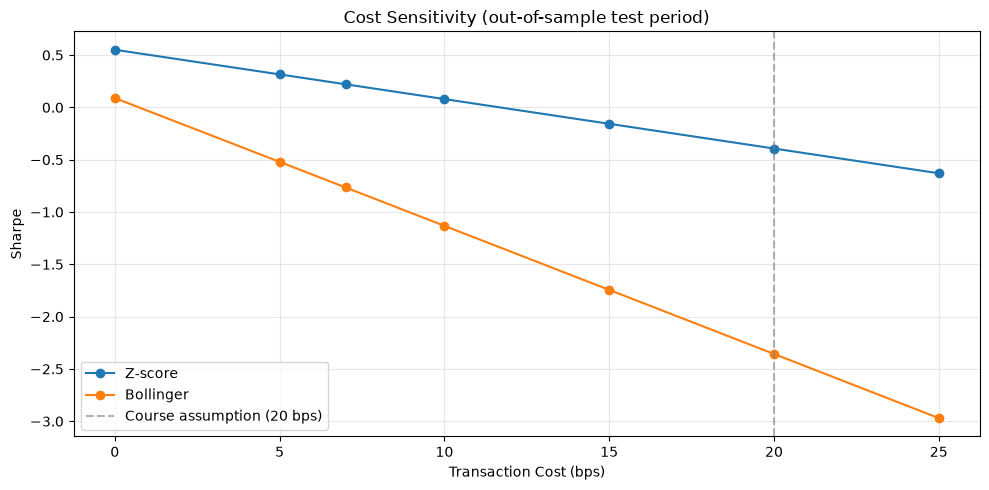

In [51]:
fee_grid = [0, 5, 7, 10, 15, 20, 25]   

cost_rows = []
for fee in fee_grid:
    _, z_rs, _ = run_pairs(test_best_z, z_selected_pairs, "zscore", Z_ENTRY, fee)
    z_ret, _, _ = apply_fixed_weights(z_rs, z_weights)
    m = portfolio_metrics_hourly(z_ret)
    cost_rows.append({"Strategy": "Z-score", "Fee_bps": fee, **m})

    _, bb_rs, _ = run_pairs(test_best_bb, bb_selected_pairs, "bollinger", BB_K, fee)
    bb_ret, _, _ = apply_fixed_weights(bb_rs, bb_weights)
    m = portfolio_metrics_hourly(bb_ret)
    cost_rows.append({"Strategy": "Bollinger", "Fee_bps": fee, **m})

cost_df = pd.DataFrame(cost_rows)
display(cost_df)
# change to zscore and bollinger side by side instead of alternating

plt.figure(figsize=(10, 5))
for strat in ["Z-score", "Bollinger"]:
    sub = cost_df[cost_df["Strategy"] == strat].sort_values("Fee_bps")
    plt.plot(sub["Fee_bps"], sub["Sharpe (hourly)"], marker="o", label=strat)
plt.axvline(20, color="gray", linestyle="--", alpha=0.6, label="Course assumption (20 bps)")
plt.title("Cost Sensitivity (out-of-sample test period)")
plt.xlabel("Transaction Cost (bps)")
plt.ylabel("Sharpe")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
def coin_exposure(test_bts, weights):
    exposure = {}
    for pair_name, w in weights.items():
        if w == 0 or pair_name not in test_bts:
            continue
        a, b = pair_name.split("/")
        bt = test_bts[pair_name]
        exposure[a] = exposure.get(a, 0.0) + w * bt["w_a"].abs().mean()
        exposure[b] = exposure.get(b, 0.0) + w * bt["w_b"].abs().mean()
    return pd.Series(exposure).sort_values(ascending=False)


z_coin_exposure = coin_exposure(z_test_bts, z_w_applied)
bb_coin_exposure = coin_exposure(bb_test_bts, bb_w_applied)

coin_exp_df = pd.concat(
    [z_coin_exposure.rename("Z-score"), bb_coin_exposure.rename("Bollinger")], axis=1
).fillna(0).sort_values("Z-score", ascending=False)

ax = coin_exp_df.plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_title("Gross Coin Exposure (aggregated across selected pairs)")
ax.set_ylabel("Aggregate weighted exposure")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

coin_exp_df.head(10)

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [53]:
print("Z-score pair weights:")
print(z_w_applied.sort_values(ascending=False))

print("\nBollinger pair weights:")
print(bb_w_applied.sort_values(ascending=False))

Z-score pair weights:


TypeError: DataFrame.sort_values() missing 1 required positional argument: 'by'

In [55]:
def hourly_to_daily(hourly_ret):
    equity = (1 + hourly_ret.fillna(0)).cumprod()
    daily_equity = equity.resample("1D").last().dropna()
    daily_ret = daily_equity.pct_change().dropna()
    return daily_ret

In [56]:
def daily_portfolio_metrics(daily_ret):
    daily_ret = daily_ret.dropna()
    equity = (1 + daily_ret.fillna(0)).cumprod()
    vol = daily_ret.std()
    sharpe = np.nan if vol == 0 or np.isnan(vol) else (daily_ret.mean() / vol) * np.sqrt(365)
    max_dd = (equity / equity.cummax() - 1).min()
    return {
        "Sharpe (daily)": sharpe,
        "Cumulative Return": equity.iloc[-1] - 1 if len(equity) else np.nan,
        "Max Drawdown": max_dd,
        "N Days": len(daily_ret),
    }

In [57]:
def benchmark_stats(port_daily_ret, btc_daily_ret):
    aligned = pd.concat(
        [port_daily_ret.rename("port"), btc_daily_ret.rename("btc")], axis=1
    ).dropna()
    X = sm.add_constant(aligned["btc"])
    model = sm.OLS(aligned["port"], X).fit()
    return {
        "Corr_to_BTC": aligned["port"].corr(aligned["btc"]),
        "Beta_to_BTC": model.params["btc"],
        "Alpha_Annualized": model.params["const"] * 365,
        "Alpha_tstat": model.tvalues["const"],
    }

In [58]:
btc_test_prices = test_prices.set_index("timestamp")["BTC"]
btc_daily_ret = btc_test_prices.resample("1D").last().dropna().pct_change().dropna()

z_daily_ret = hourly_to_daily(z_port_ret)
bb_daily_ret = hourly_to_daily(bb_port_ret)

final_rows = {}
for name, daily_ret in [("Z-score", z_daily_ret), ("Bollinger", bb_daily_ret)]:
    row = daily_portfolio_metrics(daily_ret)
    row.update(benchmark_stats(daily_ret, btc_daily_ret))
    final_rows[name] = row

final_summary = pd.DataFrame(final_rows).T
print(f"Final out-of-sample summary at {FEE_BPS_MAIN:.0f} bps, daily-aggregated:")
final_summary

Final out-of-sample summary at 20 bps, daily-aggregated:


,Sharpe (daily),Cumulative Return,Max Drawdown,N Days,Corr_to_BTC,Beta_to_BTC,Alpha_Annualized,Alpha_tstat
Z-score,-0.612439,-0.069370,-0.160382,472.0,-0.012050,-0.002311,-0.051092,-0.683199
Bollinger,-0.911992,-0.035002,-0.049785,472.0,-0.113762,-0.007640,-0.024178,-0.929154


In [59]:
paired = z_test_metrics.set_index("Pair")["Sharpe"].rename("Sharpe_Z").to_frame()
paired["Sharpe_BB"] = bb_test_metrics.set_index("Pair")["Sharpe"]
paired = paired.dropna()

# print(f"N pairs compared: {len(paired)}")
# print(ttest_rel(paired["Sharpe_Z"], paired["Sharpe_BB"]))

plt.figure(figsize=(12, 5))
plt.plot((1 + z_port_ret.fillna(0)).cumprod(), label="Z-score")
plt.plot((1 + bb_port_ret.fillna(0)).cumprod(), label="Bollinger")
plt.title(f"Out-of-Sample Equity Curves ({FEE_BPS_MAIN:.0f} bps)")
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'z_test_metrics' is not defined